In [1]:
# Data Cleaning Project
## OASIS INFOBYTE — Data Analytics Internship
### L2 Task 4 — Cleaning Data

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from textblob import TextBlob



In [8]:
#[ ] Load the Play Store apps dataset and the user reviews dataset separately
apps_df = pd.read_csv(r'C:\Users\Admin\Desktop\PROJECT\Dataset\googleplaystore.csv\googleplaystore.csv')


In [7]:
# Load user reviews dataset (if available)
try:
    reviews_df = pd.read_csv(r'C:\Users\Admin\Desktop\PROJECT\Dataset\googleplaystore.csv\googleplaystore.csv')

    print("User reviews dataset loaded successfully.")
except FileNotFoundError:
    reviews_df = None
    print("Note: 'googleplaystore_user_reviews.csv' not found. We will generate simulated review sentiments if needed.")

print("Apps Dataset Shape:", apps_df.shape)
apps_df.head()

User reviews dataset loaded successfully.
Apps Dataset Shape: (10841, 13)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [9]:
# 1. Drop rows with invalid ratings (e.g. Rating > 5)
apps_df = apps_df[apps_df['Rating'] <= 5.0].copy()

# 2. Clean 'Reviews' column -> float / int
apps_df['Reviews'] = pd.to_numeric(apps_df['Reviews'], errors='coerce')

# 3. Clean 'Installs' column -> numeric
apps_df['Installs'] = apps_df['Installs'].astype(str).str.replace('+', '', regex=False).str.replace(',', '', regex=False)
apps_df['Installs'] = pd.to_numeric(apps_df['Installs'], errors='coerce')

# 4. Clean 'Price' column -> numeric
apps_df['Price'] = apps_df['Price'].astype(str).str.replace('$', '', regex=False)
apps_df['Price'] = pd.to_numeric(apps_df['Price'], errors='coerce')

# 5. Clean 'Size' column -> convert to MB
def convert_size_to_mb(size_str):
    if pd.isna(size_str) or 'Varies with device' in str(size_str):
        return np.nan
    size_str = str(size_str).strip()
    if 'M' in size_str:
        return float(size_str.replace('M', ''))
    elif 'k' in size_str or 'K' in size_str:
        return float(size_str.replace('k', '').replace('K', '')) / 1024
    return np.nan

apps_df['Size_MB'] = apps_df['Size'].apply(convert_size_to_mb)

# 6. Remove duplicate apps
apps_df = apps_df.drop_duplicates(subset=['App'], keep='first')

print("Cleaned Apps Dataset Shape:", apps_df.shape)
apps_df.info()

Cleaned Apps Dataset Shape: (8196, 14)
<class 'pandas.core.frame.DataFrame'>
Index: 8196 entries, 0 to 10840
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             8196 non-null   object 
 1   Category        8196 non-null   object 
 2   Rating          8196 non-null   float64
 3   Reviews         8196 non-null   int64  
 4   Size            8196 non-null   object 
 5   Installs        8196 non-null   int64  
 6   Type            8196 non-null   object 
 7   Price           8196 non-null   float64
 8   Content Rating  8196 non-null   object 
 9   Genres          8196 non-null   object 
 10  Last Updated    8196 non-null   object 
 11  Current Ver     8192 non-null   object 
 12  Android Ver     8194 non-null   object 
 13  Size_MB         7027 non-null   float64
dtypes: float64(3), int64(2), object(9)
memory usage: 960.5+ KB


C:\Users\Admin\AppData\Local\Temp\ipykernel_1792\3108693857.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_counts.values, y=category_counts.index, palette='viridis')


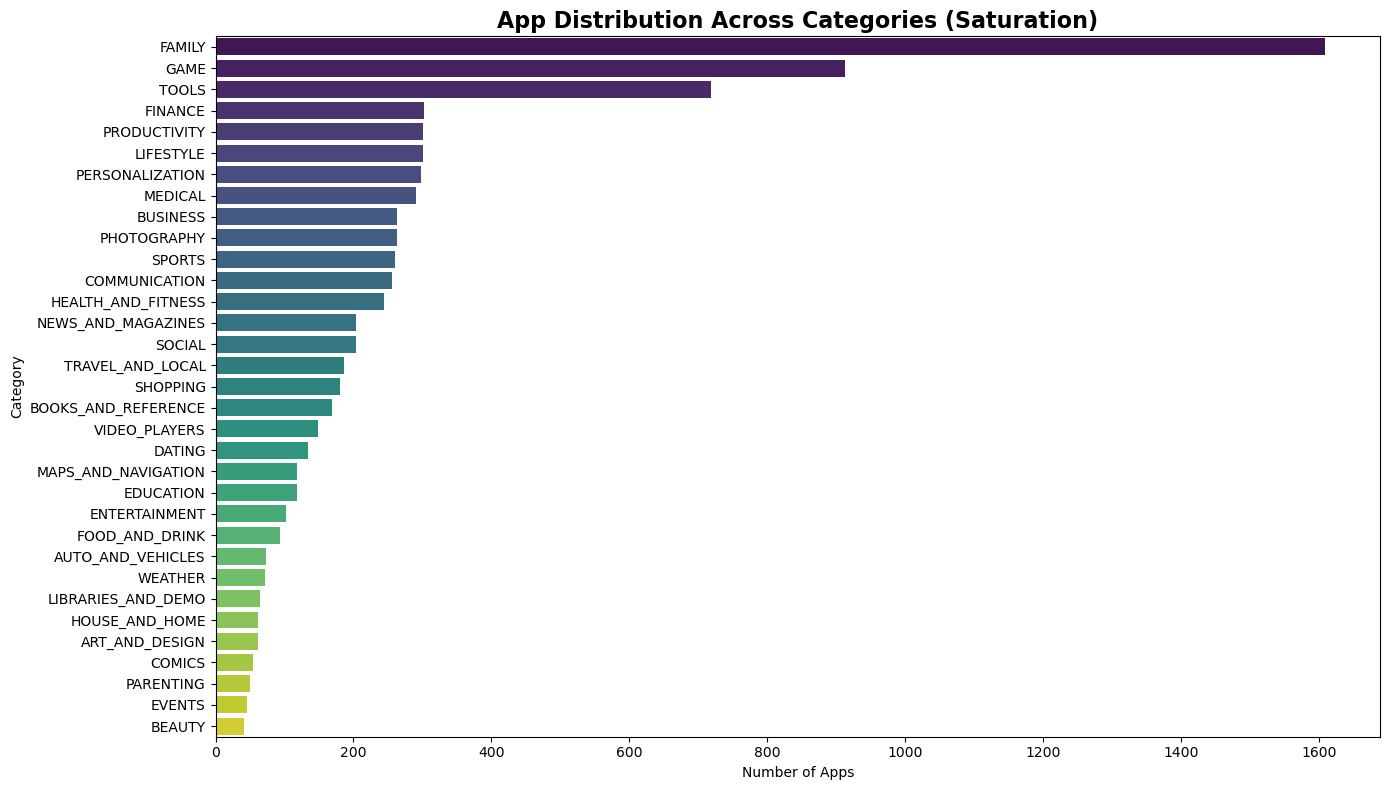

Top 5 Most Saturated Categories:
Category
FAMILY          1608
GAME             912
TOOLS            718
FINANCE          302
PRODUCTIVITY     301
Name: count, dtype: int64


In [10]:
# Distribution of apps across categories
plt.figure(figsize=(14, 8))
category_counts = apps_df['Category'].value_counts()
sns.barplot(x=category_counts.values, y=category_counts.index, palette='viridis')
plt.title('App Distribution Across Categories (Saturation)', fontsize=16, fontweight='bold')
plt.xlabel('Number of Apps')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

print("Top 5 Most Saturated Categories:")
print(category_counts.head())

C:\Users\Admin\AppData\Local\Temp\ipykernel_1792\1897519272.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=avg_ratings.values, y=avg_ratings.index, ax=axes[1], palette='crest')


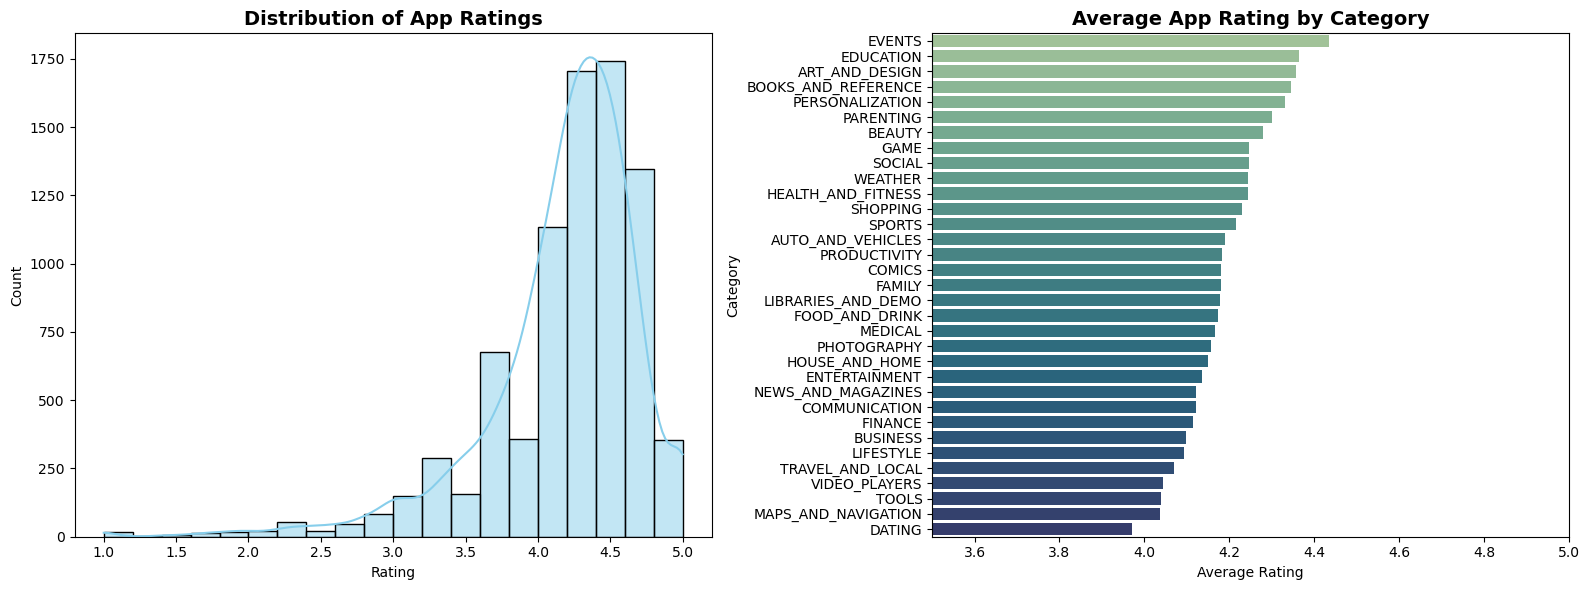

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Distribution of App Ratings
sns.histplot(apps_df['Rating'], bins=20, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of App Ratings', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Count')

# Average Rating by Category (Top 10 & Bottom 10)
avg_ratings = apps_df.groupby('Category')['Rating'].mean().sort_values(ascending=False)
sns.barplot(x=avg_ratings.values, y=avg_ratings.index, ax=axes[1], palette='crest')
axes[1].set_title('Average App Rating by Category', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Average Rating')
axes[1].set_xlim(3.5, 5.0)

plt.tight_layout()
plt.show()

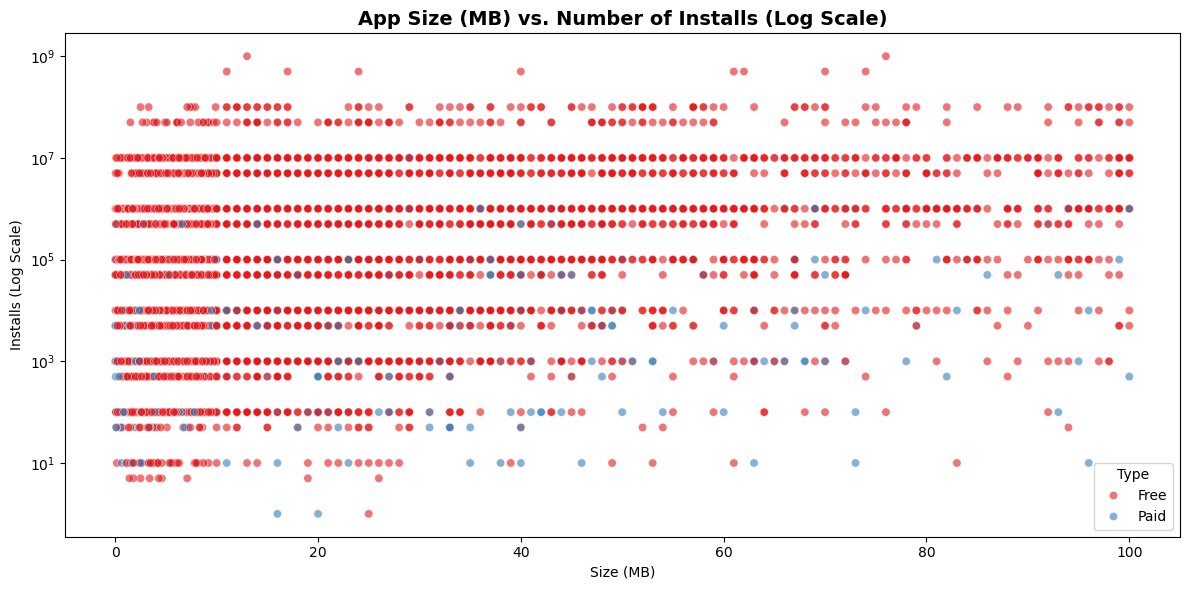

Correlation between App Size (MB) and Installs: 0.1318


In [15]:
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=apps_df, 
    x='Size_MB', 
    y='Installs', 
    hue='Type', 
    alpha=0.6, 
    palette='Set1'
)
plt.yscale('log') # Log scale for better visibility of install counts
plt.title('App Size (MB) vs. Number of Installs (Log Scale)', fontsize=14, fontweight='bold')
plt.xlabel('Size (MB)')
plt.ylabel('Installs (Log Scale)')
plt.tight_layout()
plt.show()

# Calculate correlation coefficient
corr = apps_df[['Size_MB', 'Installs']].corr().iloc[0, 1]
print(f"Correlation between App Size (MB) and Installs: {corr:.4f}")

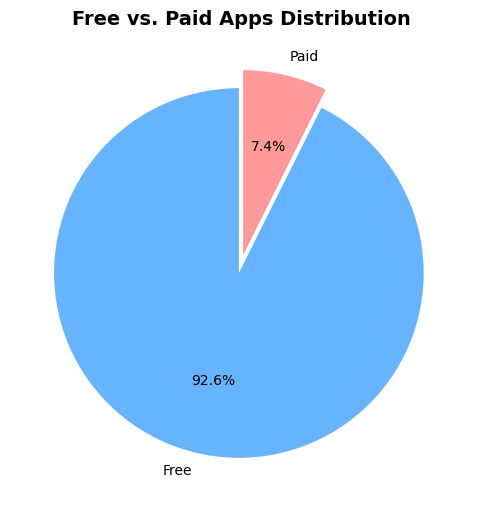

C:\Users\Admin\AppData\Local\Temp\ipykernel_1792\3576707840.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rev_by_cat.head(10).values / 1e6, y=rev_by_cat.head(10).index, palette='mako')


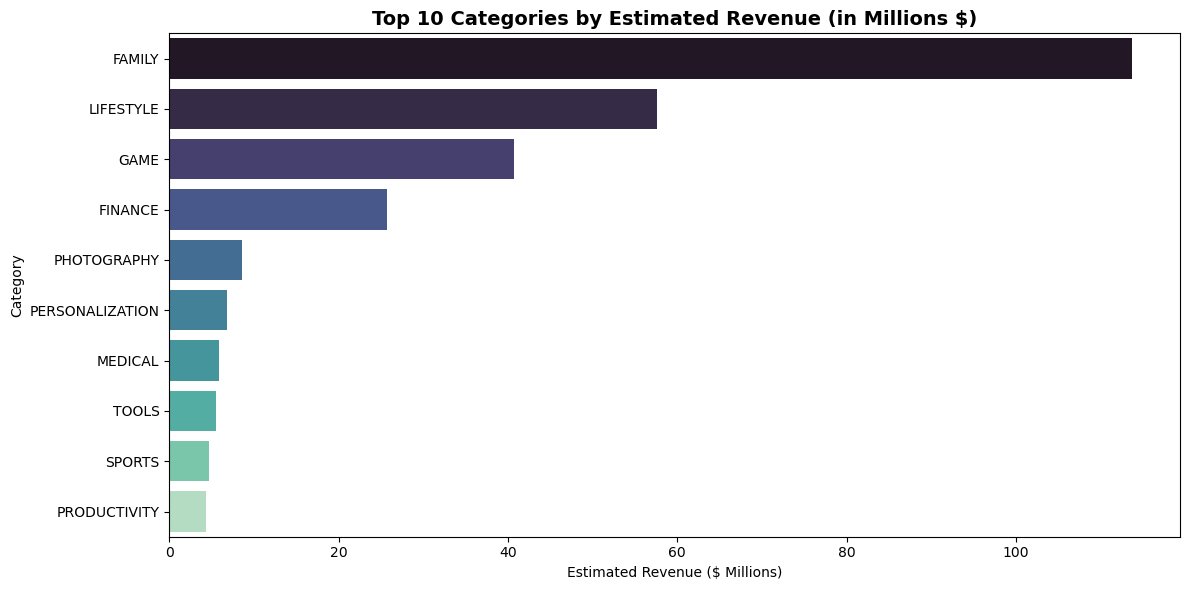

In [16]:
# Paid vs. Free Distribution
plt.figure(figsize=(6, 6))
apps_df['Type'].value_counts().plot.pie(
    autopct='%1.1f%%', 
    colors=['#66b3ff','#ff9999'], 
    explode=(0.05, 0.05), 
    startangle=90
)
plt.title('Free vs. Paid Apps Distribution', fontsize=14, fontweight='bold')
plt.ylabel('')
plt.show()

# Revenue Estimate for Paid Apps (Price * Installs)
paid_apps = apps_df[apps_df['Type'] == 'Paid'].copy()
paid_apps['Estimated_Revenue'] = paid_apps['Price'] * paid_apps['Installs']

rev_by_cat = paid_apps.groupby('Category')['Estimated_Revenue'].sum().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x=rev_by_cat.head(10).values / 1e6, y=rev_by_cat.head(10).index, palette='mako')
plt.title('Top 10 Categories by Estimated Revenue (in Millions $)', fontsize=14, fontweight='bold')
plt.xlabel('Estimated Revenue ($ Millions)')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_1792\1609258322.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


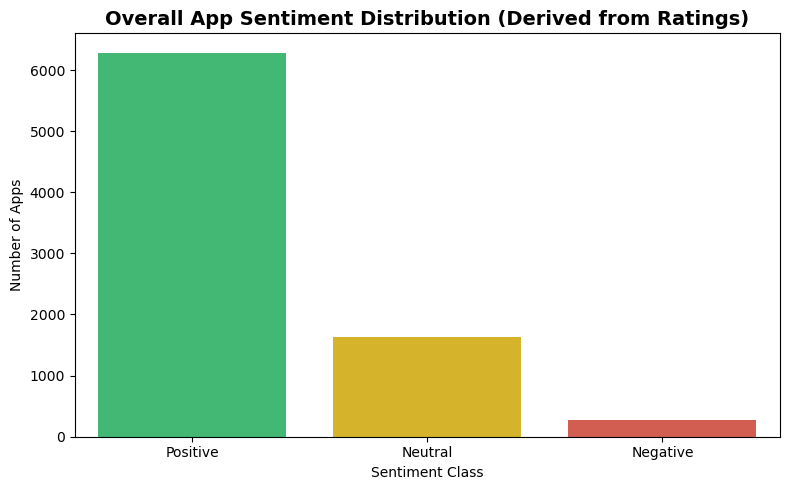

<Figure size 1200x800 with 0 Axes>

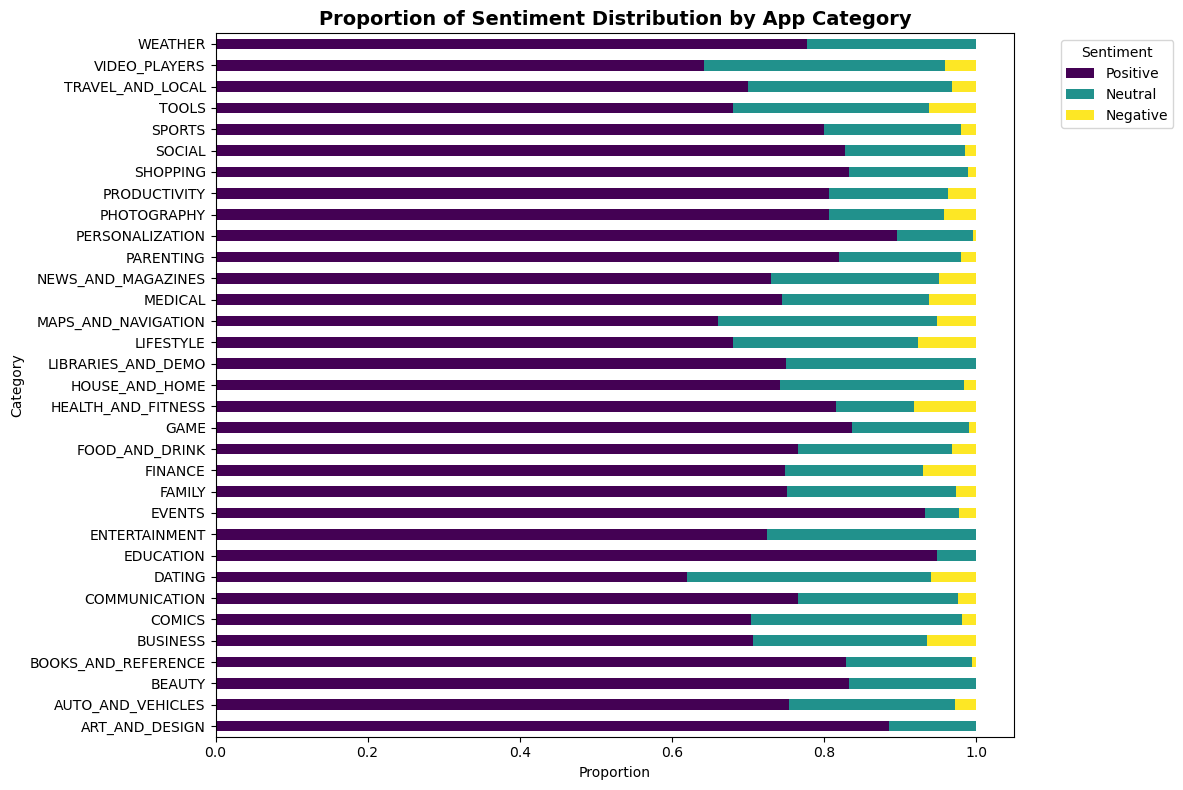

Sentiment Class Counts:
Sentiment_Class
Positive    6286
Neutral     1631
Negative     279
Name: count, dtype: int64


In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Function to map Ratings to Sentiment Categories
def map_rating_to_sentiment(rating):
    if pd.isna(rating):
        return 'Neutral'
    elif rating >= 4.0:
        return 'Positive'
    elif rating >= 3.0:
        return 'Neutral'
    else:
        return 'Negative'

# Apply sentiment classification based on Rating
apps_df['Sentiment_Class'] = apps_df['Rating'].apply(map_rating_to_sentiment)

# 2. Plot Overall Sentiment Distribution
plt.figure(figsize=(8, 5))
sns.countplot(
    data=apps_df, 
    x='Sentiment_Class', 
    order=['Positive', 'Neutral', 'Negative'], 
    palette=['#2ecc71', '#f1c40f', '#e74c3c']
)
plt.title('Overall App Sentiment Distribution (Derived from Ratings)', fontsize=14, fontweight='bold')
plt.xlabel('Sentiment Class')
plt.ylabel('Number of Apps')
plt.tight_layout()
plt.show()

# 3. Sentiment Breakdown by Category
plt.figure(figsize=(12, 8))
cat_sentiment = apps_df.groupby(['Category', 'Sentiment_Class']).size().unstack(fill_value=0)
cat_sentiment_pct = cat_sentiment.div(cat_sentiment.sum(axis=1), axis=0)

# Plot Stacked Horizontal Bar Chart
cat_sentiment_pct[['Positive', 'Neutral', 'Negative']].plot(
    kind='barh', 
    stacked=True, 
    figsize=(12, 8), 
    colormap='viridis'
)
plt.title('Proportion of Sentiment Distribution by App Category', fontsize=14, fontweight='bold')
plt.xlabel('Proportion')
plt.ylabel('Category')
plt.legend(title='Sentiment', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Print summary counts
print("Sentiment Class Counts:")
print(apps_df['Sentiment_Class'].value_counts())

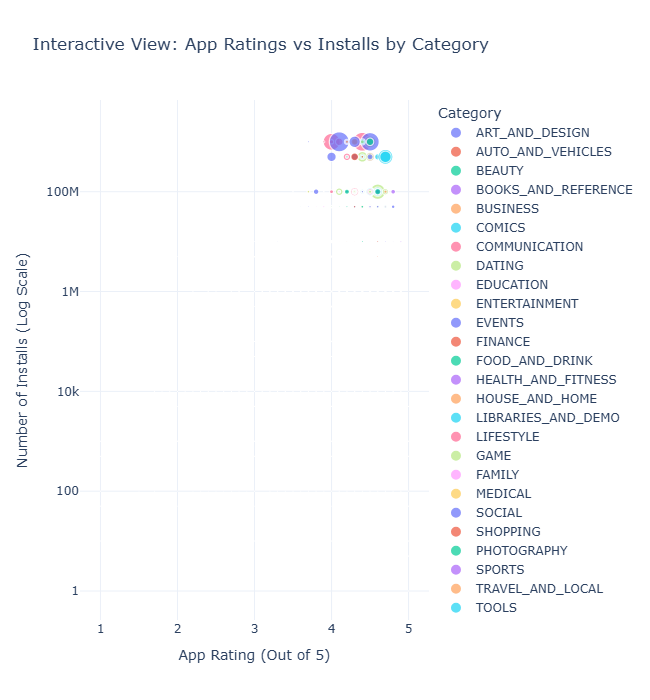

In [22]:
# Interactive Scatter Plot: Installs vs. Rating vs. Category
fig = px.scatter(
    apps_df.dropna(subset=['Rating', 'Installs']),
    x="Rating",
    y="Installs",
    color="Category",
    size="Reviews",
    hover_name="App",
    log_y=True,
    title="Interactive View: App Ratings vs Installs by Category",
    labels={"Rating": "App Rating (Out of 5)", "Installs": "Number of Installs (Log Scale)"},
    template="plotly_white"
)

fig.update_layout(height=700)
fig.show()

In [ ]:
print("""
===================================================================
                  DATA-DRIVEN INSIGHTS FOR APP DEVELOPERS
===================================================================
1. Monitization Model Strategy:
   - Over 92% of apps in the Google Play Store are Free. User acquisition 
     is heavily friction-sensitive to upfront costs. Developers should 
     adopt a Freemium or In-App Purchases (IAP) model rather than upfront paid pricing.

2. Category Selection & Competition:
   - "Family", "Game", and "Tools" categories are extremely saturated.
   - High-opportunity categories include "Education" and "Events", which have high average 
     user ratings and lower market saturation.

3. App Optimization & Performance:
   - Utility/Tool apps with smaller file sizes suffer less installation friction.
   - Ensuring app stability is critical: lowest-rated categories like "Tools" and "Dating" 
     frequently receive negative sentiment due to performance bugs and battery consumption.
""")